# Warehouse movements: exploration & forecast showcase

This notebook visualizes the real sample export (`data/ensaladilla.xls`) and the synthetic demo dataset
(`data/synthetic_inventory.csv`). All logic lives in the `warehouse_forecaster` package
(`pip install -e ".[dev]"` from the repo root). This notebook only loads data and plots it.

In [1]:
from pathlib import Path

import pandas as pd

from warehouse_forecaster.constants import DEMAND, RESTOCK
from warehouse_forecaster.data import aggregation, io
from warehouse_forecaster.models.alerts import build_alert_table, generate_alert_report
from warehouse_forecaster.models.forecast import run_forecast
from warehouse_forecaster.utils import plotting

DATA = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"

def load_real_export():
    """Fresh, cleaned copy of the real export (decimal commas, dd/mm/yyyy dates)."""
    df = io.load_movements_excel(DATA / "ensaladilla.xls")
    return io.clean_movements(df, dayfirst=True, add_daily_timeline=False)

raw = load_real_export()
print(raw.shape)
raw.head()

(3000, 6)


,Referencia,Descripción,Tipo,Cantidad,Fec. Sal. Ruta,Fecha proceso
0,D002882,-ENSALADILLA RUSA CALVO 1KG 6 UDS,Salida Almacén,2.0,02/01/2026 8:00:00,2025-12-31 16:31:34
1,D002882,-ENSALADILLA RUSA CALVO 1KG 6 UDS,Salida Almacén,3.0,02/01/2026 8:00:00,2025-12-31 16:16:07
2,D002882,-ENSALADILLA RUSA CALVO 1KG 6 UDS,Salida Almacén,1.0,02/01/2026 6:10:00,2025-12-31 14:30:20
3,D002882,-ENSALADILLA RUSA CALVO 1KG 6 UDS,Salida Almacén,6.0,02/01/2026 6:10:00,2025-12-31 14:09:03
4,D002882,-ENSALADILLA RUSA CALVO 1KG 6 UDS,Salida Almacén,1.0,31/12/2025 8:10:00,2025-12-30 21:30:34


## 1. Movement totals per hour and per day

In [2]:
by_hour, by_day = aggregation.aggregate_by_date_and_hour(load_real_export())
display(by_hour.head())
display(by_day.head())

,Tipo,Fecha,Hora_Slot,Cantidad
98,Salida Almacén,2025-01-02,16,9.0
99,Salida Almacén,2025-01-02,19,7.0
100,Salida Almacén,2025-01-02,20,4.0
101,Salida Almacén,2025-01-02,21,2.0
102,Salida Almacén,2025-01-03,17,1.0


,Tipo,Fecha,Cantidad
81,Salida Almacén,2025-01-02,22.0
82,Salida Almacén,2025-01-03,1.0
83,Salida Almacén,2025-01-07,27.0
0,Colocación Carro,2025-01-08,108.0
84,Salida Almacén,2025-01-08,41.0


## 2. Hourly outflow, gaps filled with zero (January 2025)

Very sparse at this resolution, so the daily view below is more useful.

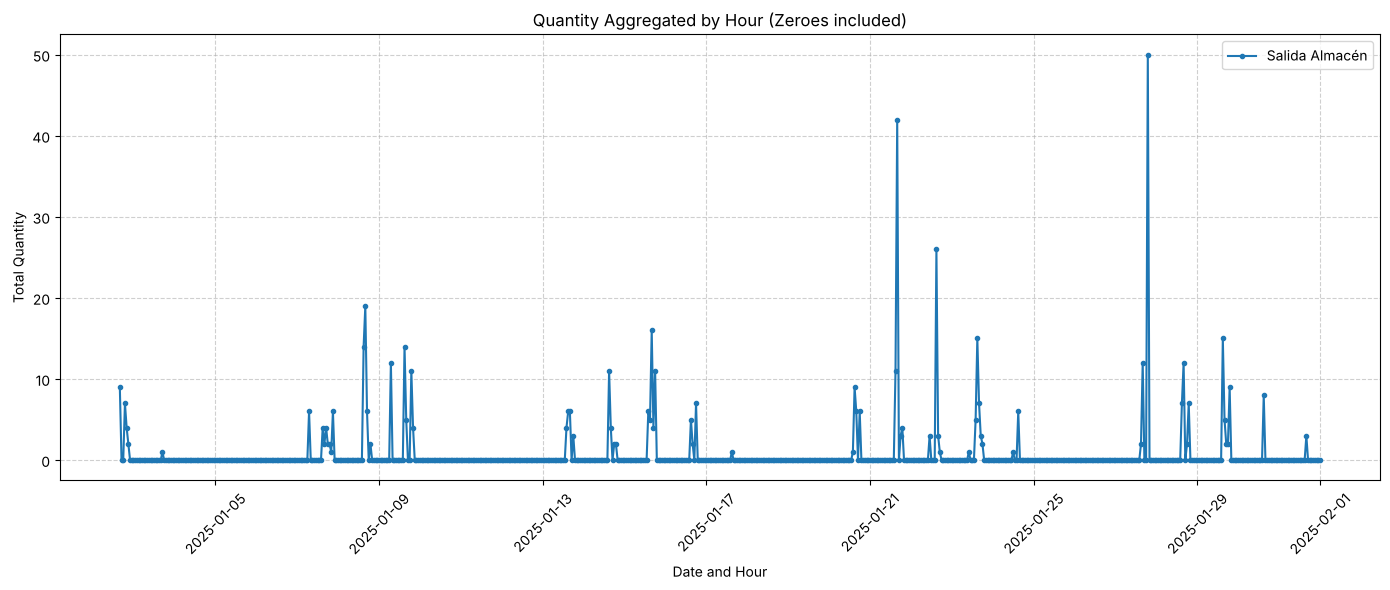

In [3]:
df = load_real_export()
aggregation.add_period_timeline(df, "h")
hourly = aggregation.fill_movement_gaps(df, "h", tipos=[DEMAND])
plotting.plot_quantities(aggregation.filter_window(hourly, "2025-01-01", "2025-02-01"),
                         "Timeline", "Quantity Aggregated by Hour (Zeroes included)", "Date and Hour")

## 3. Daily inflow vs outflow (Jan to Aug 2025)

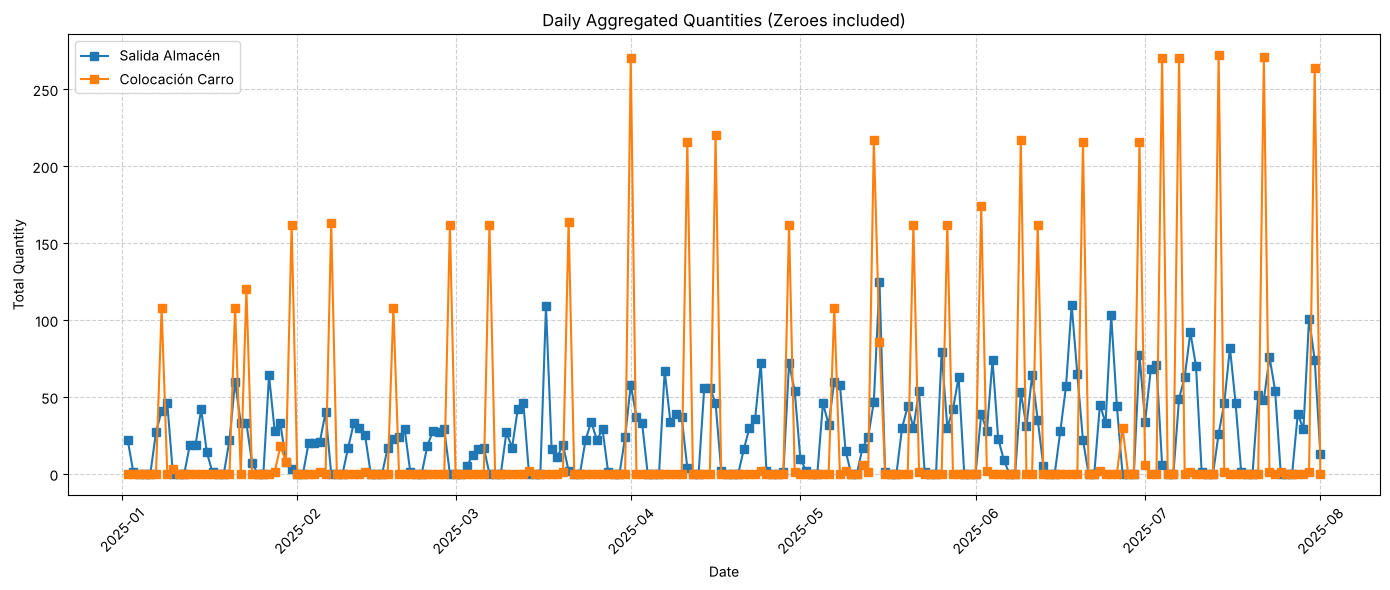

In [4]:
df = load_real_export()
df["Timeline"] = df["Fecha proceso"].dt.normalize()
daily = aggregation.fill_movement_gaps(df, "D")
plotting.plot_quantities(aggregation.filter_window(daily, "2025-01-01", "2025-08-01"),
                         "Timeline", "Daily Aggregated Quantities (Zeroes included)", "Date", marker="s")

## 4. Reconstructed stock level (min-zero baseline)

The export has no opening balance, so the initial stock is chosen so that the lowest point is exactly zero.

Auto-calculated Initial Stock: 154.0


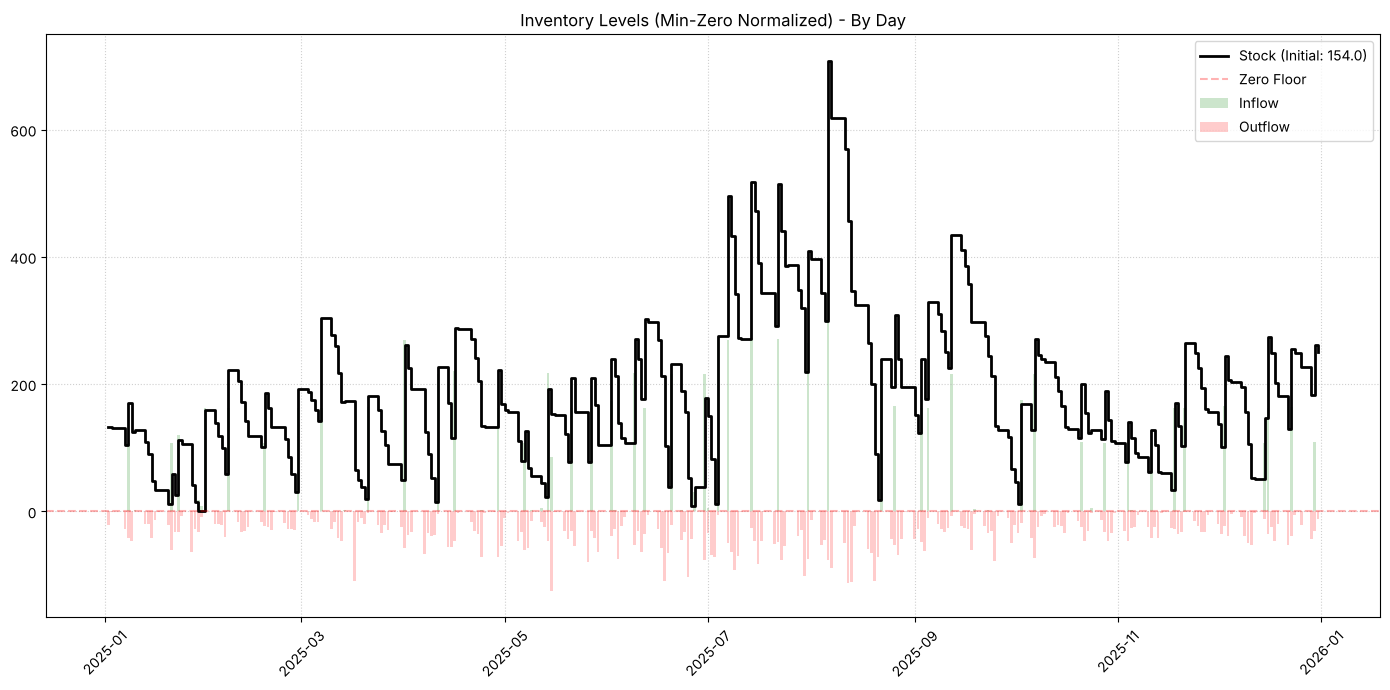

Tipo,Colocación Carro,Salida Almacén,Stock_Level
Timeline,,,
2025-01-02,0.0,22.0,132.0
2025-01-03,0.0,1.0,131.0
2025-01-04,0.0,0.0,131.0
2025-01-05,0.0,0.0,131.0
2025-01-06,0.0,0.0,131.0


In [5]:
stock_daily, init = aggregation.compute_stock_table(load_real_export(), aggregate="day")
plotting.plot_stock_levels(stock_daily, init, "day")
stock_daily.head()

/home/user/warehouse-forecaster/src/warehouse_forecaster/data/aggregation.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  subset = subset.reindex(full_range).fillna(0)
/home/user/warehouse-forecaster/src/warehouse_forecaster/data/aggregation.py:52: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  subset = subset.reindex(full_range).fillna(0)


Auto-calculated Initial Stock: 0


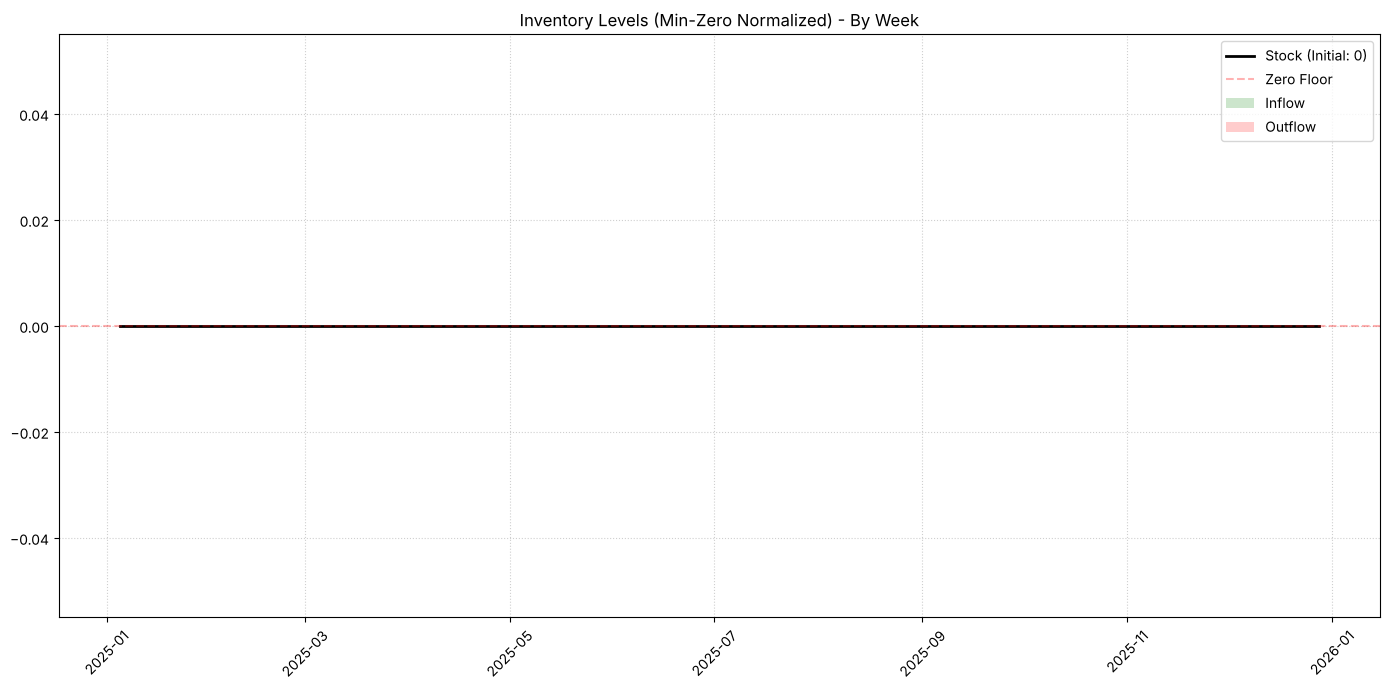

In [6]:
stock_weekly, init = aggregation.compute_stock_table(load_real_export(), aggregate="week")
plotting.plot_stock_levels(stock_weekly, init, "week")

## 5. Stockout forecast for the real item

Demand for each future day is last year's demand on the same day plus the recent trend
(the last-30-day mean minus the same window a year earlier), floored at zero.

Current stock: 250 | burn rate: 19.90/day | stockout: 2026-01-08 00:00:00


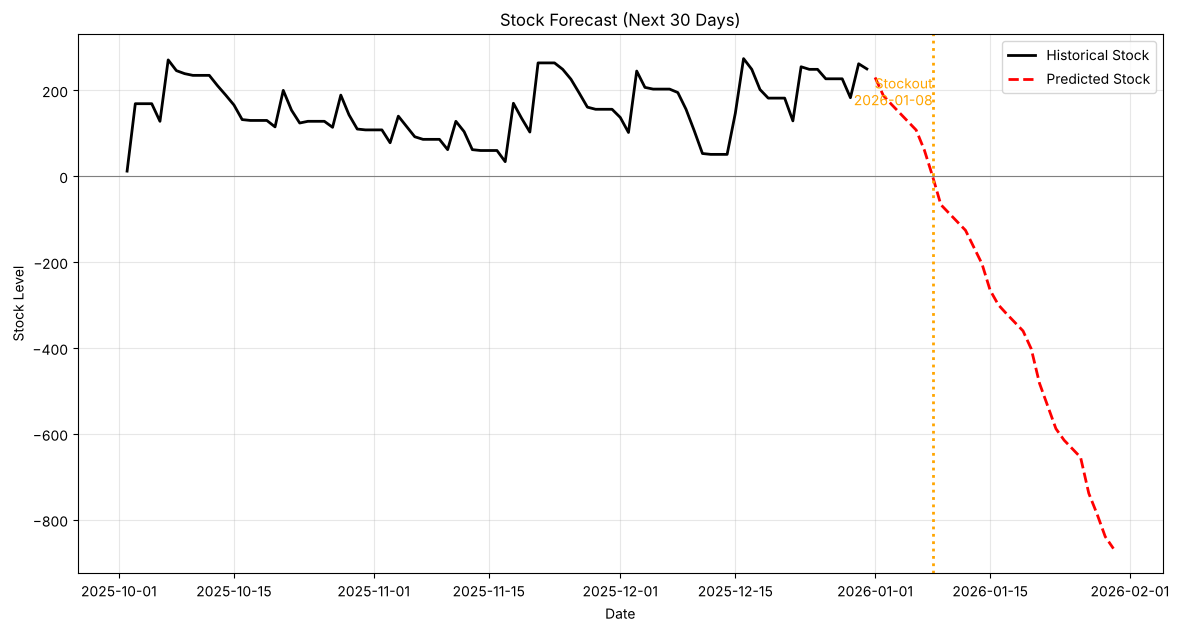

In [7]:
real = load_real_export()
real["Timeline"] = real["Fecha proceso"].dt.normalize()
result = run_forecast(real, forecast_days=30)
print(f"Current stock: {result.current_stock:.0f} | burn rate: {result.burn_rate:.2f}/day | "
      f"stockout: {result.stockout_date}")
plotting.plot_forecast(result)

## 6. Synthetic dataset: bulk stockout alerts

Regenerate the dataset with `python scripts/generate_synthetic_data.py`.

In [8]:
synthetic = io.load_inventory_csv(DATA / "synthetic_inventory.csv")
alert_table = generate_alert_report(synthetic, forecast_days=30)

Analyzing 2500 items...


Processed 500/2500...


Processed 1000/2500...


Processed 1500/2500...


Processed 2000/2500...


No stockouts predicted in the next 30 days.


Same ranking the dashboard shows: items sorted by safety margin, then by current stock.

In [9]:
ranked = build_alert_table(synthetic, forecast_days=30)
display(ranked.head(15))

,Referencia,Current Stock,Daily Burn Rate,Est. Stockout,Safety Margin
1745,ITEM_1746,544.0,1.935484,Safe,30
1992,ITEM_1993,569.0,1.258065,Safe,30
790,ITEM_0791,613.0,2.193548,Safe,30
409,ITEM_0410,666.0,1.967742,Safe,30
1393,ITEM_1394,856.0,1.677419,Safe,30
1139,ITEM_1140,911.0,0.967742,Safe,30
1851,ITEM_1852,924.0,2.064516,Safe,30
205,ITEM_0206,925.0,2.483871,Safe,30
569,ITEM_0570,949.0,2.677419,Safe,30
2003,ITEM_2004,954.0,1.903226,Safe,30


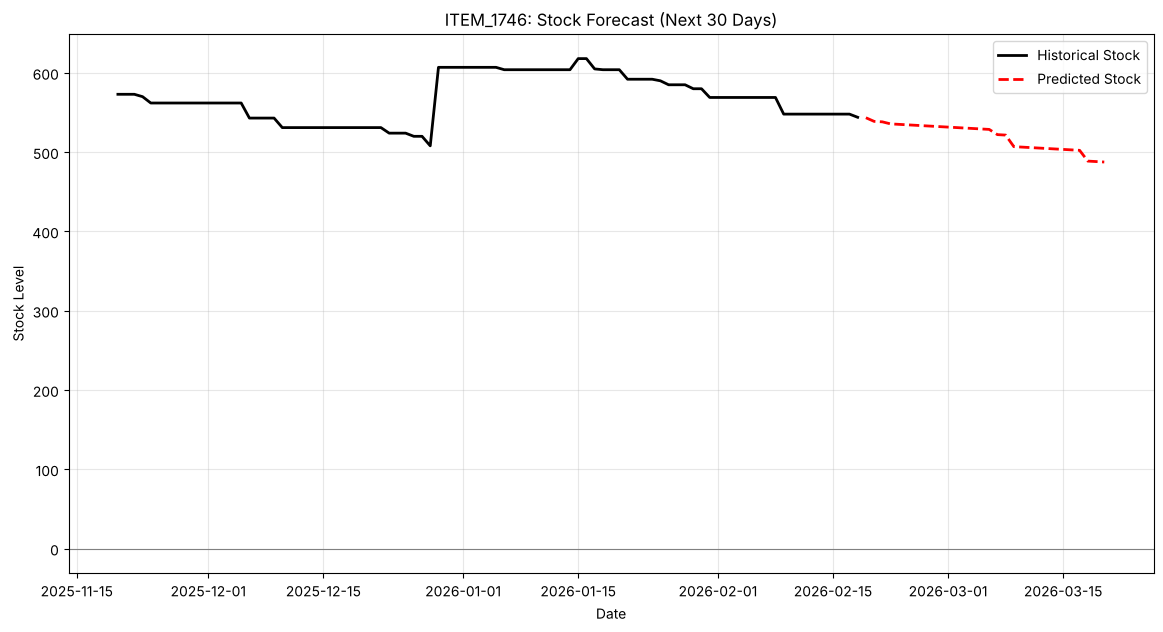

In [10]:
most_urgent = (alert_table if not alert_table.empty else ranked).iloc[0]["Referencia"]
res = run_forecast(synthetic[synthetic["Referencia"] == most_urgent], forecast_days=30)
plotting.plot_forecast(res, title=f"{most_urgent}: Stock Forecast (Next 30 Days)")